# BnSentMix — Model 5 Final Unseen-Test Evaluation

This notebook evaluates the three **already trained and validation-selected** clause-aware dual-polarity XLM-R checkpoints on the locked unseen test split. It exactly reconstructs the frozen clause splitting, balanced 128-token allocation, clause-mean pooling, evidence-specific attention, and `0.5` dual-polarity decoding.

There is **no training, threshold tuning, marker editing, model selection, or hyperparameter tuning**. Primary reporting is mean ± sample SD over seeds `13, 42, 77`; seed `42` is used for predeclared structural diagnostics. H5 and the central-RQ check remain rejected under their validation rules.

In [1]:
# Cell 1 — Imports and frozen protocol constants
from pathlib import Path
import gc
import hashlib
import json
import math
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_recall_fscore_support
)
from transformers import AutoTokenizer, XLMRobertaConfig, XLMRobertaModel
from transformers.modeling_outputs import SequenceClassifierOutput

EXPECTED_RAW_SHA256 = '148f23eb3dc40c1012a973efec920eaccc39700a74e5bcfb56806b0bf389029d'
EXPECTED_SPLIT_SHA256 = '7be81e52030967319d43ddc1e1feaf9817f9c3011a9b914265c34b5ce0ab8ec5'
EXPECTED_TEST_ROWS = 2973
LABELS = [0, 1, 2, 3]
LABEL_NAMES = {0: 'positive', 1: 'negative', 2: 'neutral', 3: 'mixed'}
MIXED_LABEL = 3
TARGET_MAP = {0: [1, 0], 1: [0, 1], 2: [0, 0], 3: [1, 1]}
EVIDENCE_THRESHOLD = 0.5
MAX_LENGTH = 128
MAX_CLAUSES = 8
CONTRAST_MARKERS = (
    'but', 'kintu', 'kinto', 'tobe', 'jodio',
    'however', 'although', 'though', 'yet'
)
RUN_SEEDS = [13, 42, 77]
REFERENCE_SEED = 42
EVAL_BATCH_SIZE = 32

DATA_PATH = Path('/kaggle/input/datasets/olidopu/bnsentmix/dataset.csv')
OUTPUT_DIR = Path('/kaggle/working/bnsentmix_model5_final_test')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('PyTorch:', torch.__version__)
print('Transformers:', transformers.__version__)
print('Device:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU')
print('Frozen clause markers:', CONTRAST_MARKERS)
print('Output directory:', OUTPUT_DIR)

PyTorch: 2.10.0+cu128
Transformers: 5.0.0
Device: Tesla T4
Frozen clause markers: ('but', 'kintu', 'kinto', 'tobe', 'jodio', 'however', 'although', 'though', 'yet')
Output directory: /kaggle/working/bnsentmix_model5_final_test


In [2]:
# Cell 2 — Locate Model 5 artifacts and verify experiment identity
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

preferred_model_dir = Path(
    '/kaggle/input/notebooks/olidopu/final-model5/bnsentmix_model5_clause_aware'
)
if preferred_model_dir.exists():
    MODEL_INPUT_DIR = preferred_model_dir
else:
    candidates = [p.parent for p in Path('/kaggle/input').rglob('experiment_manifest.json')]
    candidates = [p for p in candidates if p.name == 'bnsentmix_model5_clause_aware']
    if len(candidates) != 1:
        raise FileNotFoundError(f'Expected one saved Model 5 folder, found: {candidates}')
    MODEL_INPUT_DIR = candidates[0]

SPLIT_PATH = MODEL_INPUT_DIR.parent / 'bnsentmix_protocol_2026' / 'bnsentmix_locked_split.csv'
TOKENIZER_DIR = MODEL_INPUT_DIR / 'tokenizer'
MANIFEST_PATH = MODEL_INPUT_DIR / 'experiment_manifest.json'
CHECKPOINTS = {seed: MODEL_INPUT_DIR / f'seed_{seed}' / 'best_state.pt' for seed in RUN_SEEDS}

assert DATA_PATH.exists(), f'Dataset not found: {DATA_PATH}'
assert SPLIT_PATH.exists(), f'Locked split not found: {SPLIT_PATH}'
assert TOKENIZER_DIR.exists(), f'Tokenizer not found: {TOKENIZER_DIR}'
assert MANIFEST_PATH.exists(), f'Experiment manifest not found: {MANIFEST_PATH}'
for seed, path in CHECKPOINTS.items():
    assert path.exists(), f'Seed {seed} checkpoint not found: {path}'
    assert path.stat().st_size > 1_000_000_000, f'Seed {seed} checkpoint appears incomplete.'

with open(MANIFEST_PATH, encoding='utf-8') as handle:
    manifest = json.load(handle)
assert manifest['dataset_sha256'] == EXPECTED_RAW_SHA256
assert manifest['split_sha256'] == EXPECTED_SPLIT_SHA256
assert manifest['run_seeds'] == RUN_SEEDS
assert manifest['contrast_markers'] == list(CONTRAST_MARKERS)
assert int(manifest['max_clauses']) == MAX_CLAUSES
assert int(manifest['max_length']) == MAX_LENGTH
assert np.isclose(float(manifest['evidence_threshold']), EVIDENCE_THRESHOLD)

raw_sha = sha256_file(DATA_PATH)
split_sha = sha256_file(SPLIT_PATH)
assert raw_sha == EXPECTED_RAW_SHA256, f'Raw dataset checksum mismatch: {raw_sha}'
assert split_sha == EXPECTED_SPLIT_SHA256, f'Locked split checksum mismatch: {split_sha}'

print('Saved Model 5:', MODEL_INPUT_DIR)
print('Locked split verified:', split_sha)
print('Manifest max clauses/length:', manifest['max_clauses'], '/', manifest['max_length'])
for seed, path in CHECKPOINTS.items():
    print(f'Seed {seed}: {path.name} ({path.stat().st_size / 1024**3:.2f} GiB)')

Saved Model 5: /kaggle/input/notebooks/olidopu/final-model5/bnsentmix_model5_clause_aware
Locked split verified: 7be81e52030967319d43ddc1e1feaf9817f9c3011a9b914265c34b5ce0ab8ec5
Manifest max clauses/length: 8 / 128
Seed 13: best_state.pt (1.04 GiB)
Seed 42: best_state.pt (1.04 GiB)
Seed 77: best_state.pt (1.04 GiB)


In [3]:
# Cell 3 — Load only the sealed test partition
split_df = pd.read_csv(SPLIT_PATH)
required_columns = {'source_row_id', 'group_id', 'text', 'label', 'split'}
assert required_columns.issubset(split_df.columns), (
    f'Missing split columns: {required_columns - set(split_df.columns)}'
)
assert split_df.groupby('group_id')['split'].nunique().max() == 1, 'Group leakage detected.'
test_df = split_df.loc[split_df['split'].eq('test')].copy().reset_index(drop=True)
test_df['label'] = test_df['label'].astype(int)
assert len(test_df) == EXPECTED_TEST_ROWS, f'Expected {EXPECTED_TEST_ROWS} rows, got {len(test_df)}'
assert sorted(test_df['label'].unique().tolist()) == LABELS

distribution = (
    test_df['label'].value_counts().sort_index()
    .rename(index=LABEL_NAMES).rename('support').to_frame()
)
display(distribution)
print('Sealed unseen-test rows:', len(test_df))

,support
label,
positive,768
negative,922
neutral,1030
mixed,253


Sealed unseen-test rows: 2973


In [4]:
# Cell 4 — Frozen dual-polarity mapping and clause segmentation
def labels_to_evidence(labels):
    return np.asarray([TARGET_MAP[int(label)] for label in labels], dtype=np.int64)

def evidence_to_labels(evidence):
    evidence = np.asarray(evidence).astype(int)
    positive_on = evidence[:, 0] == 1
    negative_on = evidence[:, 1] == 1
    labels = np.full(len(evidence), 2, dtype=int)
    labels[positive_on & ~negative_on] = 0
    labels[~positive_on & negative_on] = 1
    labels[positive_on & negative_on] = 3
    return labels

CONTRAST_REGEX = re.compile(
    r'\b(?:' + '|'.join(map(re.escape, CONTRAST_MARKERS)) + r')\b',
    flags=re.IGNORECASE
)
PUNCTUATION_REGEX = re.compile(r'[.!?,;]+')

def split_clauses(text):
    text = re.sub(r'\s+', ' ', str(text)).strip()
    if not text:
        return ['']
    boundaries = set()
    for match in PUNCTUATION_REGEX.finditer(text):
        if 0 < match.end() < len(text):
            boundaries.add(match.end())
    for match in CONTRAST_REGEX.finditer(text):
        if 0 < match.start() < len(text):
            boundaries.add(match.start())
    clauses, start = [], 0
    for boundary in sorted(boundaries) + [len(text)]:
        clause = text[start:boundary].strip()
        if clause:
            clauses.append(clause)
        start = boundary
    if not clauses:
        clauses = [text]
    if len(clauses) > MAX_CLAUSES:
        clauses = clauses[:MAX_CLAUSES - 1] + [' '.join(clauses[MAX_CLAUSES - 1:])]
    return clauses

true_evidence = labels_to_evidence(test_df['label'])
assert np.array_equal(evidence_to_labels(true_evidence), test_df['label'].to_numpy())

In [5]:
# Cell 5 — Exact clause-aligned tokenization and collator
tokenizer = AutoTokenizer.from_pretrained(
    TOKENIZER_DIR, use_fast=True, local_files_only=True
)
assert tokenizer.vocab_size == 250002, f'Unexpected tokenizer vocabulary: {tokenizer.vocab_size}'

def balanced_prefix_lengths(tokenized_clauses, budget):
    allocations = [0] * len(tokenized_clauses)
    while budget > 0:
        progressed = False
        for index, token_ids in enumerate(tokenized_clauses):
            if budget == 0:
                break
            if allocations[index] < len(token_ids):
                allocations[index] += 1
                budget -= 1
                progressed = True
        if not progressed:
            break
    return allocations

def encode_clause_text(text):
    clauses = split_clauses(text)
    tokenized_clauses = [
        tokenizer.encode(clause, add_special_tokens=False) for clause in clauses
    ]
    separator_count = max(len(clauses) - 1, 0)
    token_budget = MAX_LENGTH - 2 - separator_count
    allocations = balanced_prefix_lengths(tokenized_clauses, token_budget)
    input_ids = [tokenizer.cls_token_id]
    clause_ids = [-1]
    for clause_index, (token_ids, keep_count) in enumerate(zip(tokenized_clauses, allocations)):
        if clause_index > 0:
            input_ids.append(tokenizer.sep_token_id)
            clause_ids.append(-1)
        input_ids.extend(token_ids[:keep_count])
        clause_ids.extend([clause_index] * keep_count)
    input_ids.append(tokenizer.sep_token_id)
    clause_ids.append(-1)
    assert len(input_ids) <= MAX_LENGTH
    return {
        'input_ids': input_ids,
        'attention_mask': [1] * len(input_ids),
        'clause_ids': clause_ids
    }

class ClauseTestDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame['text'].astype(str).tolist()
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, index):
        return encode_clause_text(self.texts[index])

class ClauseInferenceCollator:
    def __call__(self, features):
        features = [dict(feature) for feature in features]
        clause_ids = [feature.pop('clause_ids') for feature in features]
        batch = tokenizer.pad(
            features, padding=True,
            pad_to_multiple_of=8 if DEVICE.type == 'cuda' else None,
            return_tensors='pt'
        )
        padded_length = batch['input_ids'].shape[1]
        batch['clause_ids'] = torch.tensor([
            ids + [-1] * (padded_length - len(ids)) for ids in clause_ids
        ], dtype=torch.long)
        return batch

test_loader = DataLoader(
    ClauseTestDataset(test_df), batch_size=EVAL_BATCH_SIZE, shuffle=False,
    collate_fn=ClauseInferenceCollator(), num_workers=2,
    pin_memory=(DEVICE.type == 'cuda')
)
print('Tokenizer loaded locally. Test batches:', len(test_loader))

Tokenizer loaded locally. Test batches: 93


In [6]:
# Cell 6 — Exact clause-aware dual-polarity architecture
class ClauseAwareDualPolarityModel(nn.Module):
    def __init__(self, max_clauses):
        super().__init__()
        config = XLMRobertaConfig(
            vocab_size=250002, hidden_size=768, num_hidden_layers=12,
            num_attention_heads=12, intermediate_size=3072, hidden_act='gelu',
            hidden_dropout_prob=0.1, attention_probs_dropout_prob=0.1,
            max_position_embeddings=514, type_vocab_size=1,
            initializer_range=0.02, layer_norm_eps=1e-5,
            pad_token_id=1, bos_token_id=0, eos_token_id=2,
            position_embedding_type='absolute', use_cache=True
        )
        self.encoder = XLMRobertaModel(config)
        self.config = self.encoder.config
        self.config.num_labels = 2
        self.config.problem_type = 'multi_label_classification'
        self.max_clauses = int(max_clauses)
        hidden_size = self.config.hidden_size
        dropout_rate = getattr(self.config, 'classifier_dropout', None)
        if dropout_rate is None:
            dropout_rate = self.config.hidden_dropout_prob
        self.dropout = nn.Dropout(dropout_rate)
        self.positive_query = nn.Parameter(torch.empty(hidden_size))
        self.negative_query = nn.Parameter(torch.empty(hidden_size))
        self.positive_head = nn.Linear(hidden_size * 2, 1)
        self.negative_head = nn.Linear(hidden_size * 2, 1)
        self._initialize_new_parameters()

    def _initialize_new_parameters(self):
        std = getattr(self.config, 'initializer_range', 0.02)
        nn.init.normal_(self.positive_query, mean=0.0, std=std)
        nn.init.normal_(self.negative_query, mean=0.0, std=std)
        for head in (self.positive_head, self.negative_head):
            nn.init.normal_(head.weight, mean=0.0, std=std)
            nn.init.zeros_(head.bias)

    @staticmethod
    def _query_pool(clause_vectors, valid_clauses, query):
        scores = torch.einsum('bkh,h->bk', clause_vectors, query)
        scores = scores / math.sqrt(clause_vectors.shape[-1])
        scores = scores.masked_fill(~valid_clauses, -1e4)
        weights = torch.softmax(scores, dim=1) * valid_clauses.to(scores.dtype)
        weights = weights / weights.sum(dim=1, keepdim=True).clamp_min(1e-8)
        return torch.sum(clause_vectors * weights.unsqueeze(-1), dim=1)

    def forward(self, input_ids=None, attention_mask=None, clause_ids=None, **kwargs):
        encoder_output = self.encoder(
            input_ids=input_ids, attention_mask=attention_mask, **kwargs
        )
        token_vectors = encoder_output.last_hidden_state
        if attention_mask is None:
            attention_mask = torch.ones_like(input_ids)
        clause_vectors, valid_clauses = [], []
        for clause_index in range(self.max_clauses):
            mask = (clause_ids == clause_index) & attention_mask.bool()
            counts = mask.sum(dim=1, keepdim=True)
            pooled = torch.sum(token_vectors * mask.unsqueeze(-1), dim=1)
            pooled = pooled / counts.clamp_min(1).to(token_vectors.dtype)
            clause_vectors.append(pooled)
            valid_clauses.append(counts.squeeze(1) > 0)
        clause_vectors = torch.stack(clause_vectors, dim=1)
        valid_clauses = torch.stack(valid_clauses, dim=1)
        positive_context = self._query_pool(clause_vectors, valid_clauses, self.positive_query)
        negative_context = self._query_pool(clause_vectors, valid_clauses, self.negative_query)
        global_context = token_vectors[:, 0, :]
        positive_logit = self.positive_head(self.dropout(torch.cat(
            [global_context, positive_context], dim=1
        )))
        negative_logit = self.negative_head(self.dropout(torch.cat(
            [global_context, negative_context], dim=1
        )))
        return SequenceClassifierOutput(logits=torch.cat([positive_logit, negative_logit], dim=1))

preview_model = ClauseAwareDualPolarityModel(MAX_CLAUSES)
TOTAL_PARAMETERS = sum(parameter.numel() for parameter in preview_model.parameters())
print(f'Exact architecture parameters: {TOTAL_PARAMETERS:,}')
del preview_model
gc.collect()

Exact architecture parameters: 278,048,258


0

In [7]:
# Cell 7 — Metrics, decoding, checkpoint loading, and inference
def load_exact_state(path):
    try:
        payload = torch.load(path, map_location='cpu', weights_only=True)
    except TypeError:
        payload = torch.load(path, map_location='cpu')
    assert isinstance(payload, dict) and 'model_state_dict' in payload
    return payload['model_state_dict']

def sigmoid_numpy(logits):
    logits = np.clip(np.asarray(logits), -50, 50)
    return 1.0 / (1.0 + np.exp(-logits))

def decode_logits(logits):
    probabilities = sigmoid_numpy(logits)
    evidence_predictions = (probabilities >= EVIDENCE_THRESHOLD).astype(int)
    return probabilities, evidence_predictions, evidence_to_labels(evidence_predictions)

def calculate_metrics(labels, predictions, true_ev, predicted_ev):
    mixed_precision, mixed_recall, mixed_f1, mixed_support = precision_recall_fscore_support(
        labels, predictions, labels=[MIXED_LABEL], average=None, zero_division=0
    )
    return {
        'accuracy': float(accuracy_score(labels, predictions)),
        'macro_f1': float(f1_score(labels, predictions, labels=LABELS, average='macro', zero_division=0)),
        'weighted_f1': float(f1_score(labels, predictions, labels=LABELS, average='weighted', zero_division=0)),
        'mixed_precision': float(mixed_precision[0]),
        'mixed_recall': float(mixed_recall[0]),
        'mixed_f1': float(mixed_f1[0]),
        'mixed_support': int(mixed_support[0]),
        'positive_evidence_f1': float(f1_score(true_ev[:, 0], predicted_ev[:, 0], zero_division=0)),
        'negative_evidence_f1': float(f1_score(true_ev[:, 1], predicted_ev[:, 1], zero_division=0)),
        'evidence_exact_match': float(np.mean(np.all(true_ev == predicted_ev, axis=1)))
    }

def predict_checkpoint(checkpoint_path):
    model = ClauseAwareDualPolarityModel(MAX_CLAUSES)
    state = load_exact_state(checkpoint_path)
    model.load_state_dict(state, strict=True)
    del state
    model.to(DEVICE)
    model.eval()
    logits_parts = []
    with torch.inference_mode():
        for batch in test_loader:
            batch = {key: value.to(DEVICE, non_blocking=True) for key, value in batch.items()}
            with torch.autocast(
                device_type=DEVICE.type, dtype=torch.float16,
                enabled=(DEVICE.type == 'cuda')
            ):
                logits = model(**batch).logits
            logits_parts.append(logits.float().cpu())
    logits = torch.cat(logits_parts).numpy()
    probabilities, evidence_predictions, predictions = decode_logits(logits)
    del model, logits_parts
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return probabilities, evidence_predictions, predictions

In [8]:
# Cell 8 — One-time unseen-test evaluation for all frozen seeds
y_true = test_df['label'].to_numpy()
seed_rows, seed_outputs, seed_reports, seed_confusions = [], {}, {}, {}
for seed in RUN_SEEDS:
    print(f'\nEvaluating frozen seed {seed} ...')
    probabilities, evidence_predictions, predictions = predict_checkpoint(CHECKPOINTS[seed])
    assert len(predictions) == len(test_df)
    metrics = calculate_metrics(y_true, predictions, true_evidence, evidence_predictions)
    seed_rows.append({'seed': seed, **metrics})
    seed_outputs[seed] = {
        'probabilities': probabilities, 'evidence_predictions': evidence_predictions,
        'predictions': predictions
    }
    seed_reports[seed] = pd.DataFrame(classification_report(
        y_true, predictions, labels=LABELS,
        target_names=[LABEL_NAMES[label] for label in LABELS],
        output_dict=True, zero_division=0
    )).T
    seed_confusions[seed] = pd.DataFrame(
        confusion_matrix(y_true, predictions, labels=LABELS),
        index=[f'true_{LABEL_NAMES[x]}' for x in LABELS],
        columns=[f'pred_{LABEL_NAMES[x]}' for x in LABELS]
    )
    output = test_df[['source_row_id', 'group_id', 'text', 'label']].copy()
    output['label_name'] = output['label'].map(LABEL_NAMES)
    output['clause_count'] = output['text'].map(lambda x: len(split_clauses(x)))
    output['has_contrast_marker'] = output['text'].map(lambda x: bool(CONTRAST_REGEX.search(str(x))))
    output['positive_probability'] = probabilities[:, 0]
    output['negative_probability'] = probabilities[:, 1]
    output['positive_evidence_prediction'] = evidence_predictions[:, 0]
    output['negative_evidence_prediction'] = evidence_predictions[:, 1]
    output['prediction'] = predictions
    output['prediction_name'] = output['prediction'].map(LABEL_NAMES)
    output['correct'] = output['label'].eq(output['prediction'])
    output.to_csv(OUTPUT_DIR / f'FINAL_test_predictions_seed_{seed}.csv', index=False)
    seed_reports[seed].to_csv(OUTPUT_DIR / f'FINAL_classification_report_seed_{seed}.csv')
    seed_confusions[seed].to_csv(OUTPUT_DIR / f'FINAL_confusion_matrix_seed_{seed}.csv')
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()})

seed_results = pd.DataFrame(seed_rows).sort_values('seed').reset_index(drop=True)
display(seed_results.round(4))


Evaluating frozen seed 13 ...
{'accuracy': 0.7316, 'macro_f1': 0.704, 'weighted_f1': 0.7301, 'mixed_precision': 0.6667, 'mixed_recall': 0.5138, 'mixed_f1': 0.5804, 'mixed_support': 253, 'positive_evidence_f1': 0.784, 'negative_evidence_f1': 0.7781, 'evidence_exact_match': 0.7316}

Evaluating frozen seed 42 ...
{'accuracy': 0.7309, 'macro_f1': 0.7072, 'weighted_f1': 0.73, 'mixed_precision': 0.6571, 'mixed_recall': 0.5455, 'mixed_f1': 0.5961, 'mixed_support': 253, 'positive_evidence_f1': 0.7897, 'negative_evidence_f1': 0.7744, 'evidence_exact_match': 0.7309}

Evaluating frozen seed 77 ...
{'accuracy': 0.736, 'macro_f1': 0.7123, 'weighted_f1': 0.7349, 'mixed_precision': 0.6765, 'mixed_recall': 0.5455, 'mixed_f1': 0.6039, 'mixed_support': 253, 'positive_evidence_f1': 0.7893, 'negative_evidence_f1': 0.7803, 'evidence_exact_match': 0.736}


,seed,accuracy,macro_f1,weighted_f1,mixed_precision,mixed_recall,mixed_f1,mixed_support,positive_evidence_f1,negative_evidence_f1,evidence_exact_match
0,13,0.7316,0.7040,0.7301,0.6667,0.5138,0.5804,253,0.7840,0.7781,0.7316
1,42,0.7309,0.7072,0.7300,0.6571,0.5455,0.5961,253,0.7897,0.7744,0.7309
2,77,0.7360,0.7123,0.7349,0.6765,0.5455,0.6039,253,0.7893,0.7803,0.7360


In [9]:
# Cell 9 — Primary three-seed mean ± sample SD
metric_columns = [
    'accuracy', 'macro_f1', 'weighted_f1',
    'mixed_precision', 'mixed_recall', 'mixed_f1',
    'positive_evidence_f1', 'negative_evidence_f1', 'evidence_exact_match'
]
mean_std = seed_results[metric_columns].agg(['mean', 'std']).T
mean_std.index.name = 'metric'
display(mean_std.round(4))
print('PAPER-READY MODEL 5 TEST RESULT')
for metric in metric_columns:
    print(f"{metric}: {mean_std.loc[metric, 'mean']:.4f} ± {mean_std.loc[metric, 'std']:.4f}")

,mean,std
metric,,
accuracy,0.7328,0.0027
macro_f1,0.7078,0.0042
weighted_f1,0.7317,0.0028
mixed_precision,0.6668,0.0097
mixed_recall,0.5349,0.0183
mixed_f1,0.5935,0.0120
positive_evidence_f1,0.7877,0.0032
negative_evidence_f1,0.7776,0.0030
evidence_exact_match,0.7328,0.0027


PAPER-READY MODEL 5 TEST RESULT
accuracy: 0.7328 ± 0.0027
macro_f1: 0.7078 ± 0.0042
weighted_f1: 0.7317 ± 0.0028
mixed_precision: 0.6668 ± 0.0097
mixed_recall: 0.5349 ± 0.0183
mixed_f1: 0.5935 ± 0.0120
positive_evidence_f1: 0.7877 ± 0.0032
negative_evidence_f1: 0.7776 ± 0.0030
evidence_exact_match: 0.7328 ± 0.0027


,precision,recall,f1-score,support
positive,0.7779,0.7617,0.7697,768.0000
negative,0.7159,0.7354,0.7255,922.0000
neutral,0.7256,0.7495,0.7373,1030.0000
mixed,0.6571,0.5455,0.5961,253.0000
accuracy,0.7309,0.7309,0.7309,0.7309
macro avg,0.7191,0.6980,0.7072,2973.0000
weighted avg,0.7303,0.7309,0.7300,2973.0000


,pred_positive,pred_negative,pred_neutral,pred_mixed
true_positive,585,56,106,21
true_negative,47,678,156,41
true_neutral,81,167,772,10
true_mixed,39,46,30,138


,subset,support,mixed_support,macro_f1,mixed_precision,mixed_recall,mixed_f1
0,all_test,2973,253,0.7072,0.6571,0.5455,0.5961
1,single_clause,2003,49,0.6015,0.2174,0.1020,0.1389
2,multiple_clauses,970,204,0.7003,0.7112,0.6520,0.6803
3,explicit_contrast_marker,231,141,0.6166,0.8000,0.8511,0.8247


,true_class,support,mean_positive_probability,mean_negative_probability,both_heads_on_rate
0,positive,768,0.7816,0.1316,0.0273
1,negative,922,0.1584,0.7264,0.0445
2,neutral,1030,0.1598,0.2143,0.0097
3,mixed,253,0.6973,0.7269,0.5455


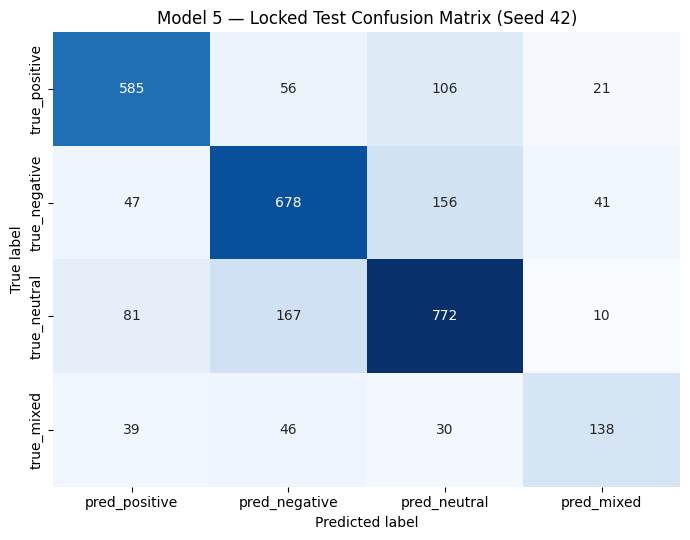

In [10]:
# Cell 10 — Reference-seed class, clause-subset, and coactivation diagnostics
reference = seed_outputs[REFERENCE_SEED]
display(seed_reports[REFERENCE_SEED].round(4))
display(seed_confusions[REFERENCE_SEED])

clause_counts = test_df['text'].map(lambda x: len(split_clauses(x))).to_numpy()
has_contrast = test_df['text'].map(lambda x: bool(CONTRAST_REGEX.search(str(x)))).to_numpy()
subset_definitions = {
    'all_test': np.ones(len(test_df), dtype=bool),
    'single_clause': clause_counts == 1,
    'multiple_clauses': clause_counts > 1,
    'explicit_contrast_marker': has_contrast
}
subset_rows = []
for subset_name, mask in subset_definitions.items():
    metrics = calculate_metrics(
        y_true[mask], reference['predictions'][mask],
        true_evidence[mask], reference['evidence_predictions'][mask]
    )
    subset_rows.append({
        'subset': subset_name, 'support': int(mask.sum()),
        'mixed_support': int(np.sum(y_true[mask] == MIXED_LABEL)),
        'macro_f1': metrics['macro_f1'],
        'mixed_precision': metrics['mixed_precision'],
        'mixed_recall': metrics['mixed_recall'],
        'mixed_f1': metrics['mixed_f1']
    })
subset_df = pd.DataFrame(subset_rows)
subset_df.to_csv(OUTPUT_DIR / 'FINAL_reference_seed_clause_subsets.csv', index=False)
display(subset_df.round(4))

coactivation_rows = []
for label in LABELS:
    mask = y_true == label
    probabilities = reference['probabilities'][mask]
    evidence = reference['evidence_predictions'][mask]
    coactivation_rows.append({
        'true_class': LABEL_NAMES[label], 'support': int(mask.sum()),
        'mean_positive_probability': float(probabilities[:, 0].mean()),
        'mean_negative_probability': float(probabilities[:, 1].mean()),
        'both_heads_on_rate': float(np.mean(np.all(evidence == 1, axis=1)))
    })
coactivation_df = pd.DataFrame(coactivation_rows)
coactivation_df.to_csv(OUTPUT_DIR / 'FINAL_reference_seed_coactivation.csv', index=False)
display(coactivation_df.round(4))

plt.figure(figsize=(7, 5.5))
sns.heatmap(seed_confusions[REFERENCE_SEED], annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Model 5 — Locked Test Confusion Matrix (Seed {REFERENCE_SEED})')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f'FINAL_confusion_matrix_seed_{REFERENCE_SEED}.png', dpi=200, bbox_inches='tight')
plt.show()

In [11]:
# Cell 11 — Save final paper-ready summary and provenance
seed_results.to_csv(OUTPUT_DIR / 'FINAL_test_seed_results.csv', index=False)
mean_std.to_csv(OUTPUT_DIR / 'FINAL_test_mean_std.csv')
final_record = {
    'model': 'M5 Clause-aware dual-polarity XLM-R',
    'split': 'locked_final_test',
    'n_test': int(len(test_df)),
    'seeds': RUN_SEEDS,
    'reference_seed_for_diagnostics': REFERENCE_SEED,
    'per_seed': seed_results.to_dict(orient='records'),
    'mean': {metric: float(mean_std.loc[metric, 'mean']) for metric in metric_columns},
    'sample_std': {metric: float(mean_std.loc[metric, 'std']) for metric in metric_columns},
    'split_sha256': EXPECTED_SPLIT_SHA256,
    'raw_sha256': EXPECTED_RAW_SHA256,
    'max_length': MAX_LENGTH, 'max_clauses': MAX_CLAUSES,
    'contrast_markers': list(CONTRAST_MARKERS),
    'evidence_threshold': EVIDENCE_THRESHOLD,
    'total_parameters': int(TOTAL_PARAMETERS),
    'validation_H5_supported': False,
    'validation_central_RQ_supported_vs_Model2': False
}
with open(OUTPUT_DIR / 'FINAL_test_metrics.json', 'w', encoding='utf-8') as handle:
    json.dump(final_record, handle, indent=2, ensure_ascii=False)
print('\nSaved files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(' -', path.name)
print('\nDo not change clause rules, thresholds, or H5 after viewing these results.')


Saved files:
 - FINAL_classification_report_seed_13.csv
 - FINAL_classification_report_seed_42.csv
 - FINAL_classification_report_seed_77.csv
 - FINAL_confusion_matrix_seed_13.csv
 - FINAL_confusion_matrix_seed_42.csv
 - FINAL_confusion_matrix_seed_42.png
 - FINAL_confusion_matrix_seed_77.csv
 - FINAL_reference_seed_clause_subsets.csv
 - FINAL_reference_seed_coactivation.csv
 - FINAL_test_mean_std.csv
 - FINAL_test_metrics.json
 - FINAL_test_predictions_seed_13.csv
 - FINAL_test_predictions_seed_42.csv
 - FINAL_test_predictions_seed_77.csv
 - FINAL_test_seed_results.csv

Do not change clause rules, thresholds, or H5 after viewing these results.


## What to keep after the run

Save the Kaggle version and retain the complete `bnsentmix_model5_final_test` folder. Keep all three prediction files plus the reference-seed clause-subset and coactivation tables; they provide the mechanism evidence for where clause-aware modelling helps and where it fails.